# **TP1 - Variable Types & Descriptive Statistics**

<b>Exploratory Data Analysis & Unsuperivsed Learning </b><br>
**Course: Dr. HAS Sothea** <br> 
**TP: Ms. UANN Sreyvi** <br>

-------

**Objective**: This initial practical session is designed to enhance your understanding of various data variable types and the corresponding statistical and graphical tools suitable for each type.

---------

> **The `Jupyter Notebook` for this TP can be downloaded here: [TP1-Gapminder](https://hassothea.github.io/I5_EDA_ITC/TPs/TP1_Variable_Types_Descriptive_Statistics.ipynb)**.

-------

# 1. `Gapminder` dataset

[`Gapminder`](https://pypi.org/project/gapminder/) is an excerpt of data available at [https://gapminder.org](https://www.gapminder.org/). For each of $142$ countries (`country`), the package provides values for life expectancy (`lifeExp`), GDP per capita (`gdpPercap`), and population (`pop`), every five years, from $1952$ to $2007$ (`year`). It is initially used in [Jennifer Bryan's excellent `gapminder` teaching package for R](https://github.com/jennybc/gapminder/) ([`ggplot`](https://ggplot2.tidyverse.org/), [`tidyverse`](https://www.tidyverse.org/), and more). For more information about `gapminder`: 
- Documentation: [https://www.gapminder.org/data/documentation/](https://www.gapminder.org/data/documentation/)
- A short demonstration video is available here: [Hans Rosling's 200 Countries, 200 Years, 4 Minutes - The Joy of Stats - BBC Four](https://youtu.be/jbkSRLYSojo?si=qipg08VIi999hEgo).

In [1]:
# useful packages
import numpy as np
import pandas as pd

# %pip install gapminder  (for installing gapminder if you haven't had one)
from gapminder import gapminder
print(f"* Number of observations: {gapminder.shape[0]}")
gapminder.sample(3)

* Number of observations: 1704


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/gapminder/data.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


,country,continent,year,lifeExp,pop,gdpPercap
1330,Senegal,Africa,2002,61.600,10870037,1519.635262
92,Bahrain,Asia,1992,72.601,529491,19035.579170
533,France,Europe,1977,73.830,53165019,18292.635140


----------

# 2. Variable types

`EDA` involves summarizing and visualizing data to uncover patterns, detect anomalies, and understand relationships between variables. Statistical summaries, such as mean, median, and standard deviation, are essential tools in this process.

- Which variables are considered quantitative and which are qualitative? 

> Hint: You can check the default column types by using `gapminder.dtypes`. But this may not be accurate because some categorical data may be encoded using numerical values.

In [2]:
gapminder.dtypes

country       object
continent     object
year           int64
lifeExp      float64
pop            int64
gdpPercap    float64
dtype: object

In [3]:
print(f"Quantitative columns: {gapminder.select_dtypes(include='number').columns.to_list()}")
print(f"Qualitative columns: {gapminder.select_dtypes(include='object').columns.to_list()}")

Quantitative columns: ['year', 'lifeExp', 'pop', 'gdpPercap']
Qualitative columns: ['country', 'continent']


> **Your response**: 
> - **Quantitative**: `lifeExp`, `pop`, `gdpPercap` (continuous / large-count numeric measurements, where means and differences are meaningful). `year` is also stored as a number, but it is just a time index (one value every 5 years), so we treat it as an ordered/discrete time variable rather than a measurement to summarize.
> - **Qualitative**: `country` (nominal, 142 levels) and `continent` (nominal, 5 levels).
> - In this dataset the default `dtypes` are therefore correct, except that `year` should be interpreted as a time label.

## 2.1 Quantitative variables

1. In year 2002, 
- Compute suitable statistics for each quantitative variable (excluding `year`) to obtain an overall summary.
- Recall the definitions of **skewness** and **kurtosis** introduced in the course. 
- Compute these metrics for each quantitative variable and explain the distribution of each variable based on these values.

In [4]:
data2002 = gapminder.query("year == 2002")
data2002.head()

,country,continent,year,lifeExp,pop,gdpPercap
10,Afghanistan,Asia,2002,42.129,25268405,726.734055
22,Albania,Europe,2002,75.651,3508512,4604.211737
34,Algeria,Africa,2002,70.994,31287142,5288.040382
46,Angola,Africa,2002,41.003,10866106,2773.287312
58,Argentina,Americas,2002,74.340,38331121,8797.640716


In [5]:
data2002[['lifeExp', 'pop',	'gdpPercap']].describe()

,lifeExp,pop,gdpPercap
count,142.000000,1.420000e+02,142.000000
mean,65.694923,4.145759e+07,9917.848365
std,12.279823,1.408483e+08,11154.114865
min,39.193000,1.703720e+05,241.165876
25%,55.522250,4.173506e+06,1409.567264
50%,70.825500,1.037292e+07,5319.804524
75%,75.459250,2.654556e+07,13359.512258
max,82.000000,1.280400e+09,44683.975250


**Skewness** measures the asymmetry of a distribution: $\gamma_1 = \mathbb{E}\left[\left(\frac{X-\mu}{\sigma}\right)^3\right]$. 
$\gamma_1 > 0$ means a long right tail (mean > median), $\gamma_1 < 0$ a long left tail (mean < median), and $\gamma_1 \approx 0$ a symmetric distribution.

**Kurtosis** measures the heaviness of the tails (and peakedness): $\gamma_2 = \mathbb{E}\left[\left(\frac{X-\mu}{\sigma}\right)^4\right]$. The normal distribution has $\gamma_2 = 3$, so `pandas` reports the **excess kurtosis** $\gamma_2 - 3$: positive means heavier tails than a normal (more outliers), negative means lighter tails / flatter shape.

In [6]:
quant_cols = ['lifeExp', 'pop', 'gdpPercap']
shape = data2002[quant_cols].agg(['skew', 'kurt']).T
shape.columns = ['skewness', 'excess kurtosis']
shape['median'] = data2002[quant_cols].median()
shape['mean'] = data2002[quant_cols].mean()
shape

,skewness,excess kurtosis,median,mean
lifeExp,-0.632298,-0.954877,7.082550e+01,6.569492e+01
pop,7.471563,59.604234,1.037292e+07,4.145759e+07
gdpPercap,1.258700,0.342356,5.319805e+03,9.917848e+03


**Interpretation (year 2002)**
- **`lifeExp`**: skewness $\approx -0.63$ → moderately **left-skewed** (mean $65.7$ < median $70.8$): most countries have a high life expectancy ($70$–$80$ years) with a tail of countries with very low values (sub-Saharan Africa, Afghanistan). Excess kurtosis $\approx -0.95$ → **flatter than a normal** with light tails, no extreme outliers (values are bounded between $39$ and $82$).
- **`pop`**: skewness $\approx 7.5$ and excess kurtosis $\approx 59.6$ → **extremely right-skewed with very heavy tails**. The mean ($41.5$M) is four times the median ($10.4$M): most countries are small, while a few giants (China $1.28$B, India $1.03$B) dominate.
- **`gdpPercap`**: skewness $\approx 1.26$ → clearly **right-skewed** (mean $9918$ > median $5320$): many poor/middle-income countries and a few very rich ones. Excess kurtosis $\approx 0.34$ → tails close to a normal distribution, so the rich countries are not extreme outliers.

2. Graphically represent the distribution of each variable for the year $2002$. After plotting the distributions, provide a brief explanation for each variable.

In [7]:
import plotly.express as px
fig = px.histogram(
    data2002,
    x = 'lifeExp'
)
# config
fig.update_layout(
    width=500,
    height=300,
    title='Histogram of life expectancy in 2002'
)
fig.show()

In [8]:
fig = px.histogram(
    data2002,
    x = 'pop',
    nbins = 40
)
fig.update_layout(
    width=500,
    height=300,
    title='Histogram of population in 2002'
)
fig.show()

# the same, with a log scale to see the bulk of the countries
fig = px.histogram(
    data2002,
    x = 'pop',
    nbins = 30,
    log_x = True
)
fig.update_layout(
    width=500,
    height=300,
    title='Histogram of population in 2002 (log scale)'
)
fig.show()

In [9]:
fig = px.histogram(
    data2002,
    x = 'gdpPercap',
    nbins = 30
)
fig.update_layout(
    width=500,
    height=300,
    title='Histogram of GDP per capita in 2002'
)
fig.show()

In [10]:
# boxplots give a complementary view (median, IQR, outliers)
for col in ['lifeExp', 'pop', 'gdpPercap']:
    fig = px.box(data2002, x=col, hover_name='country', points='outliers')
    fig.update_layout(width=500, height=220, title=f'Boxplot of {col} in 2002')
    fig.show()

**Comments**
- **`lifeExp`**: the histogram is skewed to the left with a mass of countries at $70$–$80$ years and a long tail towards $40$–$50$ years. There is one big mode at $70$–$80$ years ($68$ of the $142$ countries) and an almost flat plateau between $40$ and $70$ years (mostly African countries), which is why the kurtosis is negative (flat shape).
- **`pop`**: on the raw scale almost all countries fall into the first bin, and China and India are isolated far on the right. On a log scale the distribution becomes roughly bell-shaped, which means that population is approximately **log-normal**.
- **`gdpPercap`**: right-skewed; most countries have less than $\$15{,}000$ per capita, and the density decreases steadily towards the rich countries (up to Norway at $\$44{,}684$). The boxplot shows a few countries above the upper whisker.

3. According to the data, in 2002:
- Which country is the richest? 
- Which country is the poorest?
- Which country is the healthiest?
- Which country is the unhealthiest?

In [11]:
data2002.query("gdpPercap == gdpPercap.max()")

,country,continent,year,lifeExp,pop,gdpPercap
1150,Norway,Europe,2002,79.05,4535591,44683.97525


In [12]:
def extremes(df):
    """Richest / poorest / healthiest / unhealthiest country of a dataframe (one year)."""
    rows = {
        'richest (max gdpPercap)': df.loc[df['gdpPercap'].idxmax()],
        'poorest (min gdpPercap)': df.loc[df['gdpPercap'].idxmin()],
        'healthiest (max lifeExp)': df.loc[df['lifeExp'].idxmax()],
        'unhealthiest (min lifeExp)': df.loc[df['lifeExp'].idxmin()],
    }
    return pd.DataFrame(rows).T[['country', 'continent', 'year', 'lifeExp', 'pop', 'gdpPercap']]

extremes(data2002)

,country,continent,year,lifeExp,pop,gdpPercap
richest (max gdpPercap),Norway,Europe,2002,79.05,4535591,44683.97525
poorest (min gdpPercap),"Congo, Dem. Rep.",Africa,2002,44.966,55379852,241.165876
healthiest (max lifeExp),Japan,Asia,2002,82.0,127065841,28604.5919
unhealthiest (min lifeExp),Zambia,Africa,2002,39.193,10595811,1071.613938


**Answer (2002)**
- Richest: **Norway** ($\$44{,}684$ per capita)
- Poorest: **Congo, Dem. Rep.** ($\$241$ per capita)
- Healthiest: **Japan** ($82.0$ years)
- Unhealthiest: **Zambia** ($39.2$ years)

4. Repeat the previous question for the year 1977. Before computing, can you guess which country had the lowest life expectancy around that year?

In [13]:
gapminder.query("year == 1977").query("lifeExp == lifeExp.min()")

,country,continent,year,lifeExp,pop,gdpPercap
221,Cambodia,Asia,1977,31.22,6978607,524.972183


In [35]:
gapminder.query("year == 1977").query("country == 'Thailand'")

,country,continent,year,lifeExp,pop,gdpPercap,gdpQual,popQual,lifeExpQual
1529,Thailand,Asia,1977,62.494,44148285,1961.224635,developing,large,moderate


In [37]:
gapminder.query("year == 1977").query("country == 'Vietnam'")

,country,continent,year,lifeExp,pop,gdpPercap,gdpQual,popQual,lifeExpQual
1649,Vietnam,Asia,1977,55.764,50533506,713.53712,developing,large,unhealthy


In [14]:
data1977 = gapminder.query("year == 1977")
extremes(data1977)

,country,continent,year,lifeExp,pop,gdpPercap
richest (max gdpPercap),Kuwait,Asia,1977,69.343,1140357,59265.47714
poorest (min gdpPercap),Myanmar,Asia,1977,56.059,31528087,371.0
healthiest (max lifeExp),Iceland,Europe,1977,76.11,221823,19654.96247
unhealthiest (min lifeExp),Cambodia,Asia,1977,31.22,6978607,524.972183


**Answer (1977)**
- Richest: **Kuwait** ($\$59{,}265$), Poorest: **Myanmar** ($\$371$)
- Healthiest: **Iceland** ($76.1$ years), Unhealthiest: **Cambodia** ($31.2$ years)

*Guess before computing*: Cambodia. Around $1975$–$1979$ the Khmer Rouge regime caused a genocide, famine and forced labor that killed roughly a quarter of the population, which pushed life expectancy far below that of any other country. The computation confirms the guess: Cambodia's life expectancy dropped from $40.4$ years in $1972$ to $31.2$ in $1977$ and then recovered to $50.96$ in $1982$.

## 2.2. Qualitative variables

Qualitative variables are simpler than the quantitative ones, as we primarily focus on the proportion or frequency of each category. In our dataset, the existing qualitative variables are not suitable for analysis because they are repeated each year. Therefore, we will create three new qualitative variables associated with the three quantitative columns by copping them into three categories each.

In year 2002,

1. Add the following three variables to the `gapminder` dataset by grouping each quantitative variable into $3$ groups.
- Create variable `gdpQual` with three categories: [**"developing"**, **"moderate"**, **"developed"**] using variable `gdpPercap`.
- Create variable `popQual` with three categories: [**"small"**, **"medium"**, **"large"**] using variable `pop`.
- Create variable `lifeExpQual` with three categories: [**"unhealthy"**, **"moderate"**, **"healthy"**] using variable `lifeExp`.

> Hint: you may find `pd.cut` function helpful.

In [15]:
data2002 = data2002.copy()
data2002['gdpQual'] = pd.qcut(
    data2002['gdpPercap'],
    q=3,
    labels=["developing", "moderate", "developed"])

> Note: the three qualitative variables are built with `pd.qcut` (**tertiles**): each variable is split into three groups containing about the same number of countries in 2002. Equal-width bins (`pd.cut`) would be very unbalanced here because `gdpPercap` and especially `pop` are strongly right-skewed.

In [16]:
data2002['popQual'] = pd.qcut(
    data2002['pop'],
    q=3,
    labels=["small", "medium", "large"])
data2002['lifeExpQual'] = pd.qcut(
    data2002['lifeExp'],
    q=3,
    labels=["unhealthy", "moderate", "healthy"])
data2002.head()

,country,continent,year,lifeExp,pop,gdpPercap,gdpQual,popQual,lifeExpQual
10,Afghanistan,Asia,2002,42.129,25268405,726.734055,developing,large,unhealthy
22,Albania,Europe,2002,75.651,3508512,4604.211737,moderate,small,healthy
34,Algeria,Africa,2002,70.994,31287142,5288.040382,moderate,large,moderate
46,Angola,Africa,2002,41.003,10866106,2773.287312,moderate,medium,unhealthy
58,Argentina,Americas,2002,74.340,38331121,8797.640716,moderate,large,healthy


In [17]:
data2002.head()

,country,continent,year,lifeExp,pop,gdpPercap,gdpQual,popQual,lifeExpQual
10,Afghanistan,Asia,2002,42.129,25268405,726.734055,developing,large,unhealthy
22,Albania,Europe,2002,75.651,3508512,4604.211737,moderate,small,healthy
34,Algeria,Africa,2002,70.994,31287142,5288.040382,moderate,large,moderate
46,Angola,Africa,2002,41.003,10866106,2773.287312,moderate,medium,unhealthy
58,Argentina,Americas,2002,74.340,38331121,8797.640716,moderate,large,healthy


2. Compute the appropriate statistical values and graphically represent the distribution of each newly created qualitative variable.

In [18]:
gdp_qual = data2002.gdpQual.value_counts(normalize=True)
gdp_qual

gdpQual
developed     0.338028
developing    0.330986
moderate      0.330986
Name: proportion, dtype: float64

In [19]:
data2002['continent'].value_counts()

continent
Africa      52
Asia        33
Europe      30
Americas    25
Oceania      2
Name: count, dtype: int64

In [20]:
pop_qual = data2002['popQual'].value_counts(normalize=True)
life_qual = data2002['lifeExpQual'].value_counts(normalize=True)

# frequency table: counts + proportions of each new qualitative variable
for name in ['gdpQual', 'popQual', 'lifeExpQual']:
    freq = data2002[name].value_counts()
    table = pd.DataFrame({'count': freq, 'proportion': (freq / freq.sum()).round(3)})
    print(f"* {name}")
    display(table)

* gdpQual


,count,proportion
gdpQual,,
developed,48,0.338
developing,47,0.331
moderate,47,0.331


* popQual


,count,proportion
popQual,,
small,48,0.338
medium,47,0.331
large,47,0.331


* lifeExpQual


,count,proportion
lifeExpQual,,
healthy,48,0.338
unhealthy,47,0.331
moderate,47,0.331


- Which population range corresponds to each group?

In [21]:
data2002.groupby('popQual', observed=False)['pop'].agg(['count', 'min', 'max'])

,count,min,max
popQual,,,
small,48,170372,5410052
medium,47,5884491,19576783
large,47,20550751,1280400000


- Graphically represent them and describe the graph.

In [22]:
fig1 = px.bar(
    x = gdp_qual.index,
    y = gdp_qual.values
)
fig1.update_layout(
    width=500,
    height=400,
    title='Bar chart of qualitative GDP per capita in 2002'
)
fig1.show()

In [23]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

fig = make_subplots(rows=1, cols=3, subplot_titles=['gdpQual', 'popQual', 'lifeExpQual'], shared_yaxes=True)
for k, (prop, color) in enumerate(zip([gdp_qual, pop_qual, life_qual], ['#4C78A8', '#F58518', '#54A24B']), start=1):
    fig.add_trace(go.Bar(x=prop.index.astype(str), y=prop.values, marker_color=color, showlegend=False), row=1, col=k)
fig.update_yaxes(title_text='proportion', row=1, col=1)
fig.update_layout(width=900, height=350, title='Bar charts of the three qualitative variables in 2002')
fig.show()

**Description**
- **`gdpQual`**: by construction, the three groups are balanced ($76\%$ would be "developing" with equal-width bins; here $34\%$ / $33\%$ / $33\%$). The cut-points are about $\$2{,}141$ and $\$9{,}022$ per capita: "developing" below $\$2{,}141$, "moderate" up to $\$9{,}022$ and "developed" above.
- **`popQual`**: by construction of the tertiles, the three groups are almost perfectly balanced ($34\%$ small, $33\%$ medium, $33\%$ large), so this bar chart is flat. The cut-points are about $5.4$M and $19.6$M inhabitants. (With equal-width bins, $98.6\%$ of countries would have been "small" because of the extreme skewness of `pop`.)
- **`lifeExpQual`**: also balanced by construction ($34\%$ / $33\%$ / $33\%$) with cut-points at about $61.3$ and $73.8$ years ("unhealthy" below $61.3$ years, "healthy" above $73.8$). The left-skewness of `lifeExp` shows up in the width of the groups: the "unhealthy" group covers a wide range ($39$–$61$ years) while the "healthy" group is narrow ($74$–$82$).

---------

# 3. Time evolution

`Gapminder` captures global changes from $1952$ to $2007$. It is more insightful to examine how these variables evolve over time.

## 3.1. Evolution of quantitative columns

1. Create a line plot of `lifeExp` for the five continents from $1952$ to $2007$ using `sns.lineplot`. What observations can you make from the plot?

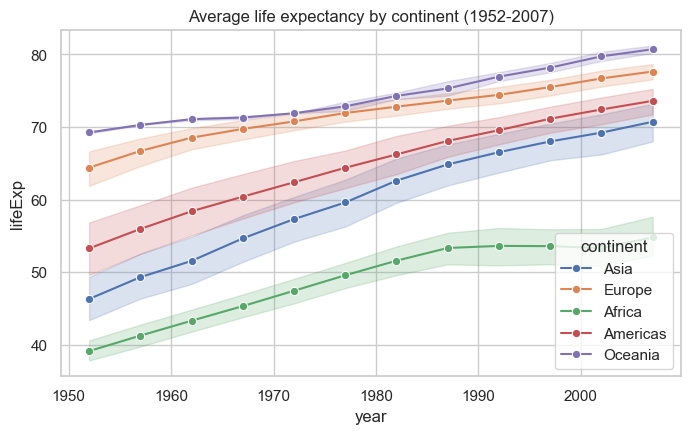

In [24]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style='whitegrid')
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.lineplot(data=gapminder, x='year', y='lifeExp', hue='continent', marker='o', ax=ax)
ax.set_title('Average life expectancy by continent (1952-2007)')
plt.show()

**Observations**: life expectancy increased in every continent between $1952$ and $2007$. Oceania and Europe are consistently on top ($69 \to 81$ and $64 \to 78$ years), the Americas and Asia follow ($53 \to 74$ and $46 \to 71$), and Africa stays at the bottom ($39 \to 55$). Asia has the fastest progress (+$24$ years) and catches up with the Americas, so the gap between continents shrinks. Africa's progress slows down after the $1990$s (the HIV/AIDS epidemic, visible as a flat part of the curve) and its large confidence band shows a strong heterogeneity between African countries.

2. Repeat the same process with `pop`, and then with `gdpPercap`. Provide your comments for each case.

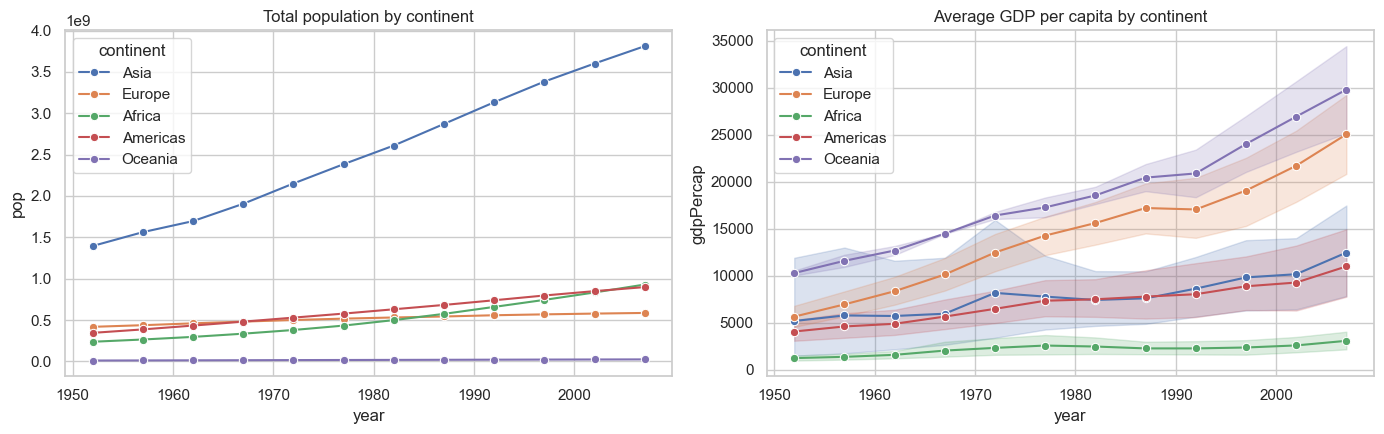

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# population: total population of each continent
sns.lineplot(data=gapminder, x='year', y='pop', hue='continent', estimator='sum', errorbar=None, marker='o', ax=axes[0])
axes[0].set_title('Total population by continent')

# GDP per capita: average over the countries of each continent
sns.lineplot(data=gapminder, x='year', y='gdpPercap', hue='continent', marker='o', ax=axes[1])
axes[1].set_title('Average GDP per capita by continent')
plt.tight_layout()
plt.show()

**Comments**
- **`pop`** (total per continent): every continent grows. Asia dominates and grows fastest ($1.4$B $\to$ $3.8$B), Africa grows the fastest in relative terms (x$3.9$, from $238$M to $930$M, overtaking Europe and even the Americas), the Americas roughly x$2.6$, whereas Europe grows slowly ($418$M $\to$ $586$M) and Oceania remains tiny (only Australia and New Zealand).
- **`gdpPercap`** (average per country): Oceania and Europe get richer and faster, with Europe accelerating strongly after $1970$ ($\$5{,}661 \to \$25{,}054$). The Americas and Asia grow moderately ($\$11{,}003$ and $\$12{,}473$ in $2007$), while Africa stays almost flat ($\$1{,}253 \to \$3{,}089$). The wide bands show large inequalities inside each continent, so the gap between rich and poor continents **increases** in absolute terms.

3. Plot the evolution of each of the three quantitative variables for **Cambodia** vs **Thailand**. Describe the graphs.

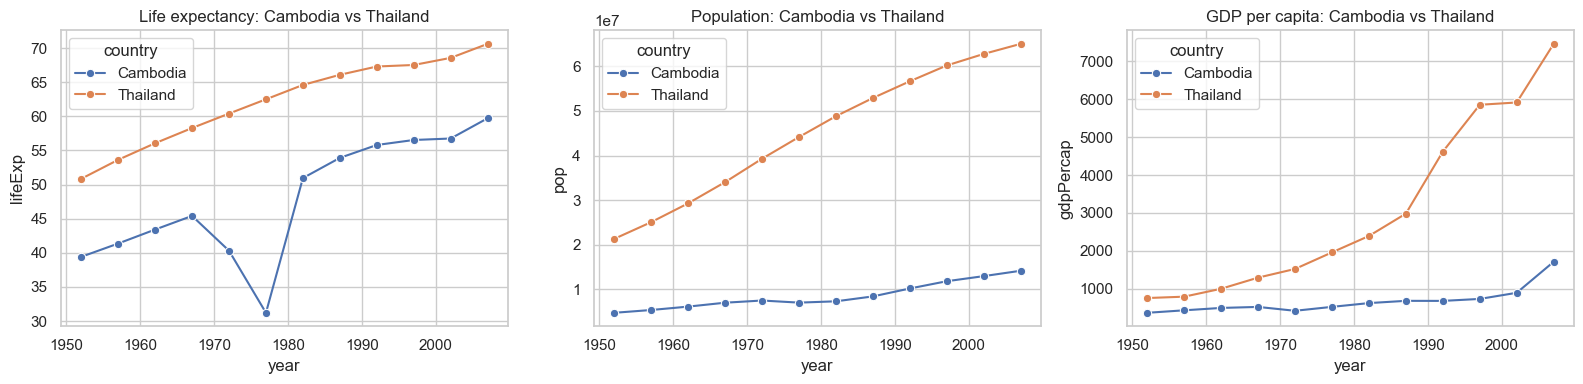

In [26]:
cmp = gapminder[gapminder['country'].isin(['Cambodia', 'Thailand'])]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col, title in zip(axes, ['lifeExp', 'pop', 'gdpPercap'],
                          ['Life expectancy', 'Population', 'GDP per capita']):
    sns.lineplot(data=cmp, x='year', y=col, hue='country', marker='o', ax=ax)
    ax.set_title(f'{title}: Cambodia vs Thailand')
plt.tight_layout()
plt.show()

**Description**
- **`lifeExp`**: Thailand has a smooth and steady increase ($51 \to 71$ years). Cambodia starts lower ($39$ years), follows the same trend until $1967$, then **collapses to $31$ years in $1977$** (Khmer Rouge regime and civil war), before recovering quickly to $60$ years in $2007$. A gap of about $11$ years remains with Thailand.
- **`pop`**: Thailand's population is always about $4$–$5$ times that of Cambodia ($65$M vs $14$M in $2007$). Both grow continuously; Cambodia is the only one with a stagnation/decrease between $1972$ and $1977$.
- **`gdpPercap`**: Thailand's GDP per capita grows steadily and exponentially ($\$758 \to \$7{,}458$), with a short slowdown around $1997$–$2002$ (Asian financial crisis). Cambodia stays low and nearly flat until $2002$ ($\$368 \to \$896$), and only starts to take off after that ($\$1{,}714$ in $2007$); in $2007$ it is still 4 times poorer than Thailand.

## 3.2. Evolution of qualitative columns

Before studying the evolution, we need the three qualitative variables for **every year**. We reuse the thresholds defined from the year $2002$ (the tertiles of $2002$), so that the categories keep the same meaning over time (e.g. "healthy" always means a life expectancy above the same threshold).

In [27]:
def qualify(df, col, labels):
    """Cut `col` into 3 categories using the tertiles computed in 2002."""
    _, edges = pd.qcut(data2002[col], 3, retbins=True)
    edges[0], edges[-1] = -np.inf, np.inf       # open the extreme bins to cover all years
    return pd.cut(df[col], bins=edges, labels=labels)

gapminder = gapminder.copy()
gapminder['gdpQual'] = qualify(gapminder, 'gdpPercap', ["developing", "moderate", "developed"])
gapminder['popQual'] = qualify(gapminder, 'pop', ["small", "medium", "large"])
gapminder['lifeExpQual'] = qualify(gapminder, 'lifeExp', ["unhealthy", "moderate", "healthy"])

# check: consistent with the 2002 categories computed above
assert (gapminder.query("year == 2002")['gdpQual'].values == data2002['gdpQual'].values).all()

def plot_qual_evolution(df, col, title):
    """Stacked bars: proportion of each category of `col` for every year."""
    prop = (df.groupby('year', observed=False)[col].value_counts(normalize=True, sort=False)
              .rename('proportion').reset_index())
    fig = px.bar(prop, x='year', y='proportion', color=col, title=title,
                 category_orders={col: list(df[col].cat.categories)},
                 color_discrete_sequence=['#E45756', '#F2CF5B', '#54A24B'])
    fig.update_layout(width=650, height=350, bargap=0.1)
    fig.show()

1. Visualize the evolution of `lifeExpQual` column in **Asia** from 1952 to 2007. What do you observe?

In [28]:
asia = gapminder.query("continent == 'Asia'")
plot_qual_evolution(asia, 'lifeExpQual', 'Evolution of lifeExpQual in Asia (1952-2007)')

**Observation**: in $1952$, $94\%$ of the Asian countries were "unhealthy" and none "healthy". The "unhealthy" group shrinks continuously ($79\%$ in $1962$, $36\%$ in $1982$, only $9\%$ in $2007$). The "moderate" group first grows (from $6\%$ to $58\%$ in $2002$), and the "healthy" group appears in the $1970$s–$1980$s and keeps growing ($9\%$ in $1982$, $36\%$ in $2007$). Asia has moved from an almost entirely unhealthy continent to one dominated by moderate and healthy countries in about $50$ years.

2. Do the same with `popQual` and `dgpQual` columns.

In [29]:
plot_qual_evolution(asia, 'popQual', 'Evolution of popQual in Asia (1952-2007)')
plot_qual_evolution(asia, 'gdpQual', 'Evolution of gdpQual in Asia (1952-2007)')

**Observations (Asia)**
- **`popQual`** (thresholds fixed at the 2002 tertiles, $5.4$M and $19.6$M): the share of "large" countries grows from $33\%$ in $1952$ to $64\%$ in $2007$, while "small" falls from $42\%$ to $21\%$ and "medium" from $24\%$ to $15\%$: Asian countries keep growing and move up the population categories.
- **`gdpQual`** (thresholds fixed at the 2002 tertiles, about $\$2{,}141$ and $\$9{,}022$): in $1952$ $70\%$ of the Asian countries were "developing" and only $6\%$ "developed". The "developing" share decreases steadily to $18\%$ in $2007$, whereas "developed" grows to $39\%$ (Japan, Singapore, Hong Kong, Kuwait, Korea, Israel, ...) and "moderate" to $42\%$: most Asian countries have crossed the poorest category, even if the continent remains heterogeneous.

3. Visualize the evolution of the three qualitative columns above for African countries from 1952 to 2007.

In [30]:
africa = gapminder.query("continent == 'Africa'")
for col in ['lifeExpQual', 'gdpQual', 'popQual']:
    plot_qual_evolution(africa, col, f'Evolution of {col} in Africa (1952-2007)')

**Observations (Africa)**
- **`lifeExpQual`**: in $1952$ all African countries are "unhealthy". The situation improves slowly until the $1990$s ("unhealthy": $100\% \to 77\%$ in $1992$, "moderate" up to $23\%$), then progress stalls and even reverses ($79\%$ still "unhealthy" in $2002$ and $2007$, only $6\%$ "healthy" in $2007$), which is consistent with the HIV/AIDS crisis.
- **`gdpQual`**: the "developing" group is still the majority but shrinks from $85\%$ in $1952$ to $69\%$ in $2007$; the "moderate" group stays around $15$–$29\%$ and "developed" appears only in the $1970$s ($4\%$) and reaches $12\%$ in $2007$ (6 countries in 2007: Botswana, Equatorial Guinea, Gabon, Libya, Mauritius and South Africa). Growth is therefore slow and unequal.
- **`popQual`**: African countries move steadily up the population scale: "small" falls from $75\%$ in $1952$ to $35\%$ in $2007$, "medium" doubles ($19\% \to 40\%$) and "large" rises from $6\%$ to $25\%$, reflecting the fast demographic growth (total population x$3.9$).
Africa is therefore lagging behind in health and, above all, in wealth, compared to Asia, while its population grows very fast.

# Further readings
- Gapminder documentation: [https://www.gapminder.org/data/documentation/](https://www.gapminder.org/data/documentation/)
- A short demonstration video is available here: [Hans Rosling's 200 Countries, 200 Years, 4 Minutes - The Joy of Stats - BBC Four](https://youtu.be/jbkSRLYSojo?si=qipg08VIi999hEgo).
- Graphical tools:
    - [`matplotlib`](https://matplotlib.org/stable/index.html)
    - [`seaborn`](https://seaborn.pydata.org/)
    - [`https://plotly.com/python/`](https://plotly.com/python/)